### Problem statement
System: In -> A -> B -> C

<br>

**In $\rightarrow$ A:** Transform Qubit Readout data. Messages arrive with fixed mean arrival rate $\lambda$. Infinite queue if stage A blocked.

**A:** Read message. Processing time $\mathrm{Uniform}(1.5, 2.2)\mu s$.

**A $\rightarrow$ B:** FIFO buffer. Capacity = 100. If full A stops

**B:** Log-Normal distribution processing time $\mu = 0.5 , \sigma ^2 = 0.5$

**B $\rightarrow$ C:** FIFO buffer. Capacity = 25. If full B stops

**C:** Constant time of $1.5\mu s$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Num Qubits through system: 2470
Mean qubit times: 19.99406352469638
Latency from enter A: 18.996999440251972
A utilisation:  0.49645804213536054
B utilisation:  0.514087954213393
C utilisation:  0.37056936472259316
Time stopped A:  0.0
Time stopped B:  0.0


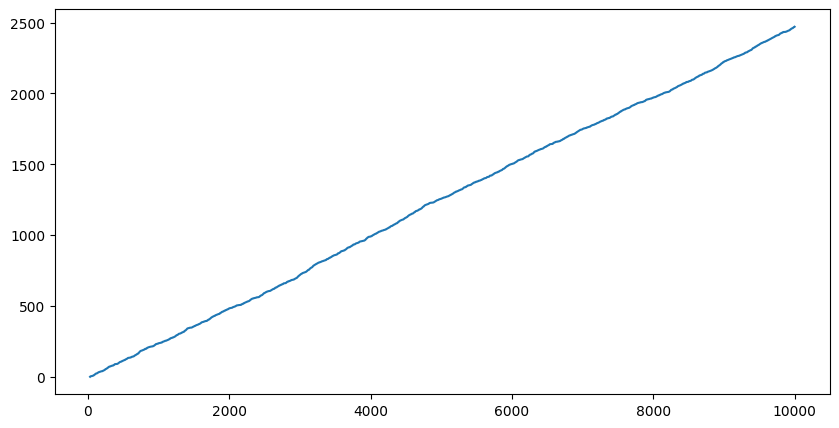

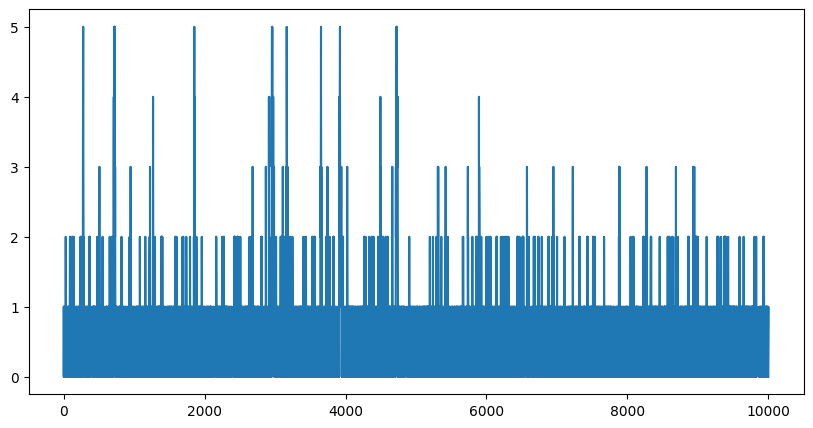

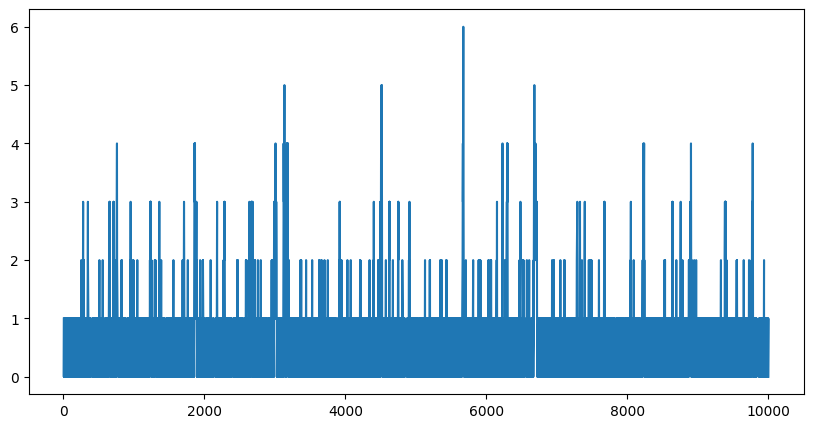

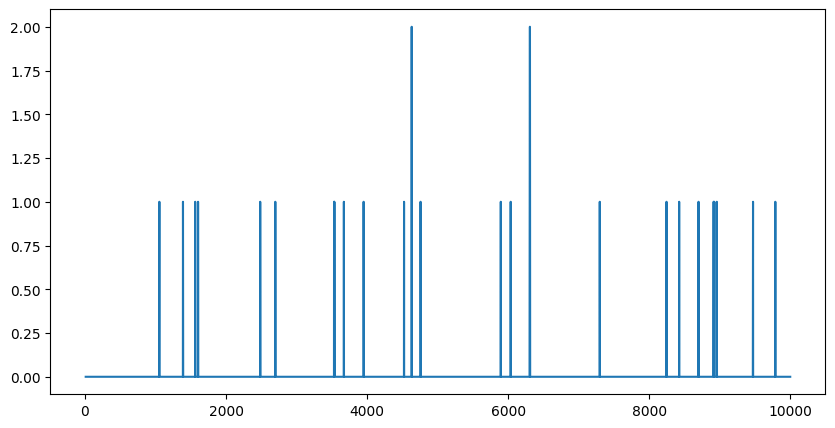

Text(0, 0.5, 'C queue length')

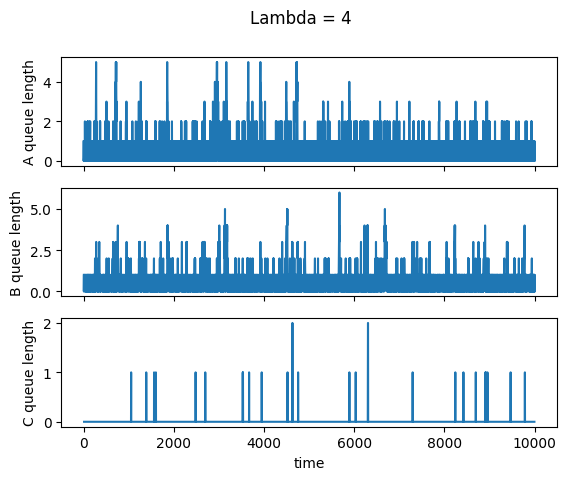

In [12]:
class Queue:
    def __init__(self, max_length):
        self.length = 0
        self.max_length = max_length

class Source:
    def __init__(self, lam):
        self.lam = lam

    def next_arrival(self):
        return np.random.exponential(scale=self.lam)


def run_sim(lam, max_time):

    b_queue = Queue(100)
    c_queue = Queue(25)
    a_queue = Queue(1e8)

    source = Source(lam)

    time = 0.0

    # Event times
    next_arrival = source.next_arrival()
    a_finish = float('inf')
    b_finish = float('inf')
    c_finish = float('inf')

    # Server states
    a_busy = False
    b_busy = False
    c_busy = False

    # Knock-on counters
    qubits_through_a = 0
    qubits_through_b = 0
    qubits_through_c = 0

    qubit_enter_a_times = []

    # Blocking
    a_stopped = False
    b_stopped = False

    last_time = 0.0

    callbacks = {
        'a_queue_lengths': [],
        'b_queue_lengths': [],
        'c_queue_lengths': [],
        'a_time_on': 0.0,
        'b_time_on': 0.0,
        'c_time_on': 0.0,
        'qubit_in_times': [],
        'latency_from_a': 0,
        'qubit_out_times': [],
        'final_queue_lengths': [0, 0, 0],
        'total_time': 0,
        'component_utilisation': {},
        'mean_time_in_system': 0,
        'times_in_system': [],
        'time_stopped_a': 0,
        'time_stopped_b': 0,
    }

    while time < max_time:

        # advance time to next event
        next_event = min(next_arrival, a_finish, b_finish, c_finish)
        prev_time = time
        time = next_event
        dt = time - prev_time

        # Gather utilisation/stopped statistics
        if a_busy:
            callbacks['a_time_on'] += dt
        if b_busy:
            callbacks['b_time_on'] += dt
        if c_busy:
            callbacks['c_time_on'] += dt

        if a_stopped:
            callbacks['time_stopped_a'] += dt
        if b_stopped:
            callbacks['time_stopped_b'] += dt

        # Event: qubit arrives
        if time == next_arrival:

            # Add qubit to A queue
            a_queue.length += 1

            # Gather statistics
            callbacks['qubit_in_times'].append(time)
            callbacks['a_queue_lengths'].append((a_queue.length, time))

            next_arrival = time + source.next_arrival()

            # Try start A if not busy/stopped
            if (not a_busy) and (a_queue.length > 0) and (not a_stopped):
                a_queue.length -= 1
                a_busy = True
                a_finish = time + (np.random.random() + 1.5)
                qubits_through_a += 1

                #Gather statistics
                qubit_enter_a_times.append(time)
                callbacks['a_queue_lengths'].append((a_queue.length, time))

        # Event: a finishes processing qubit
        elif time == a_finish:
            a_busy = False

            # Knock on to B if one already in A
            if qubits_through_a > 1:
                if b_queue.length < b_queue.max_length:
                    b_queue.length += 1

                    callbacks['b_queue_lengths'].append((b_queue.length, time))

                    # Stop A if B queue reaches capacity
                    if b_queue.length == b_queue.max_length:
                        a_stopped = True
                else:
                    a_stopped = True

                    # Prevents starting next B job if queue is full
                    continue

            # Start next A job
            if (a_queue.length > 0) and (not a_stopped):
                a_queue.length -= 1
                a_busy = True
                a_finish = time + (np.random.random() + 1.5)
                qubits_through_a += 1

                # Gather statistics
                qubit_enter_a_times.append(time)
                callbacks['a_queue_lengths'].append((a_queue.length, time))
            else:
                # Wait to get reassigned when a qubit arrives
                a_finish = float('inf')

            # Try start B
            if (not b_busy) and (b_queue.length > 0) and (not b_stopped):
                b_queue.length -= 1
                b_busy = True
                b_finish = time + np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))
                qubits_through_b += 1

                callbacks['b_queue_lengths'].append((b_queue.length, time))

        # Event. B finishes processing qubit
        elif time == b_finish:
            b_busy = False
            a_stopped = False

            # Add qubit to C queue if one already in B  component
            if qubits_through_b > 1:
                if c_queue.length < c_queue.max_length:
                    c_queue.length += 1

                    if c_queue.length == c_queue.max_length:
                        b_stopped = True
                else:
                    b_stopped = True

                    # Prevents starting next C job if queue is full
                    continue
            
            # New qubit into B component
            if (b_queue.length > 0) and (not b_stopped):
                b_queue.length -= 1
                b_busy = True
                b_finish = time + np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))
                qubits_through_b += 1

                callbacks['b_queue_lengths'].append((b_queue.length, time))
            else:
                # Wait to get reassigned when A fisishes and there is a qubit in the B queue
                b_finish = float('inf')

            # Start C if not currently in use
            if (not c_busy) and (c_queue.length > 0):
                c_queue.length -= 1
                c_busy = True
                c_finish = time + 1.5
                qubits_through_c += 1

                callbacks['c_queue_lengths'].append((c_queue.length, time))

        # Event: C finishes
        elif time == c_finish:
            c_busy = False
            b_stopped = False

            if qubits_through_c > 1:
                callbacks['qubit_out_times'].append(time)

            # Start another C job if queue exists
            if c_queue.length > 0:
                c_queue.length -= 1
                c_busy = True
                c_finish = time + 1.5
                qubits_through_c += 1

                callbacks['c_queue_lengths'].append((c_queue.length, time))
            else:
                # Same as B
                c_finish = float('inf')

    # Gathering statistics
    callbacks['final_queue_lengths'] = [
        a_queue.length,
        b_queue.length,
        c_queue.length
    ]

    callbacks['decoding_rate'] = len(callbacks['qubit_out_times']) / time

    callbacks['component_utilisation']['a'] = callbacks['a_time_on'] / time
    callbacks['component_utilisation']['b'] = callbacks['b_time_on'] / time
    callbacks['component_utilisation']['c'] = callbacks['c_time_on'] / time

    callbacks['times_in_system'] = [callbacks['qubit_out_times'][i] - callbacks['qubit_in_times'][i] for i in range(len(callbacks['qubit_out_times']))]

    callbacks['mean_time_in_system'] = np.mean(callbacks['times_in_system'])

    callbacks['latency_from_a'] = np.mean([callbacks['qubit_out_times'][i] - qubit_enter_a_times[i] for i in range(len(callbacks['qubit_out_times']))])

    callbacks['time_stopped_a'] /= time
    callbacks['time_stopped_b'] /= time

    return callbacks

lam = 4
callbacks = run_sim(lam, 10000)

print('Num Qubits through system:', len(callbacks['qubit_out_times']))

print('Mean qubit times:', callbacks['mean_time_in_system'])
print('Latency from enter A:', callbacks['latency_from_a'])

print('A utilisation: ', callbacks['component_utilisation']['a'])
print('B utilisation: ', callbacks['component_utilisation']['b'])
print('C utilisation: ', callbacks['component_utilisation']['c'])

print('Time stopped A: ', callbacks['time_stopped_a'])
print('Time stopped B: ', callbacks['time_stopped_b'])


fig = plt.figure(figsize = (10, 5))
plt.plot(callbacks['qubit_out_times'], range(1, len(callbacks['qubit_out_times'])+1))
plt.show()

y, x = zip(*callbacks['a_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['b_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['c_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

fig, axs = plt.subplots(3, sharex=True)
fig.suptitle(f'Lambda = {lam}')
y, x = zip(*callbacks['a_queue_lengths'])
axs[0].plot(x, y)
axs[0].set_ylabel('A queue length')
y, x = zip(*callbacks['b_queue_lengths'])
axs[1].plot(x, y)
axs[1].set_ylabel('B queue length')
y, x = zip(*callbacks['c_queue_lengths'])
axs[2].plot(x, y)
axs[2].set_xlabel('time')
axs[2].set_ylabel('C queue length')




## Comments

1. B seems to be bottleneck. Everything downstream is clear
2. Maybe worth doing a plot explainig how B maxing out affects A
3. Final throughput/sec should be ~1/lambda until bottleneck appears. Plot of 1/lambda vs throughput/sec
4. May be worth doing mean time from when they enter A as opposed to when they enter the queue

In [4]:
len(callbacks['qubit_in_times']), len(callbacks['qubit_out_times']), callbacks['final_queue_lengths'][0], callbacks['final_queue_lengths'][1], callbacks['final_queue_lengths'][2]

(5056, 4794, 160, 96, 0)

In [5]:
test_no = 30
lams = [0.5, 1.0, 1.5, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 3.0, 3.5, 4.0, 4.5]
latency_from_a_means = [[],[]]
total_latency_means = [[],[]]
decoding_rate = [[],[]]

a_utilisation_means = []
b_utilisation_means = []
c_utilisation_means = []

a_queue_length_means = []
b_queue_length_means = []
c_queue_length_means = []

time_stopped_a_means = []
time_stopped_b_means = []

# TODO: Investigate queue lengths
for lam in lams:

    latencies_from_a = []
    total_latencies = []
    decoding = []

    a_utilisation = []
    b_utilisation = []
    c_utilisation = []

    a_queue_length = []
    b_queue_length = []
    c_queue_length = []

    time_stopped_a = []
    time_stopped_b = []

    for _ in range(test_no):
        results = run_sim(lam, 10000)

        # Gather results for given value of lambda
        latencies_from_a.append(results['latency_from_a'])
        total_latencies.append(results['mean_time_in_system'])
        decoding.append(results['decoding_rate'])

        a_utilisation.append(results['component_utilisation']['a'])
        b_utilisation.append(results['component_utilisation']['b'])
        c_utilisation.append(results['component_utilisation']['c'])

        a_queue_length.append(np.mean(list(zip(*results['a_queue_lengths']))[0]))
        b_queue_length.append(np.mean(list(zip(*results['b_queue_lengths']))[0]))
        c_queue_length.append(np.mean(list(zip(*results['c_queue_lengths']))[0]))

        time_stopped_a.append(results['time_stopped_a'])
        time_stopped_b.append(results['time_stopped_b'])

    # Calculate means for each run
    latency_from_a_means[0].append(np.mean(latencies_from_a))
    latency_from_a_means[1].append(np.std(latencies_from_a))

    total_latency_means[0].append(np.mean(total_latencies))
    total_latency_means[1].append(np.std(total_latencies))
    
    decoding_rate[0].append(np.mean(decoding))
    decoding_rate[1].append(np.std(decoding))

    a_utilisation_means.append(np.mean(a_utilisation))
    b_utilisation_means.append(np.mean(b_utilisation))
    c_utilisation_means.append(np.mean(c_utilisation))

    a_queue_length_means.append(np.mean(a_queue_length))
    b_queue_length_means.append(np.mean(b_queue_length))
    c_queue_length_means.append(np.mean(c_queue_length))

    time_stopped_a_means.append(np.mean(time_stopped_a))
    time_stopped_b_means.append(np.mean(time_stopped_b))



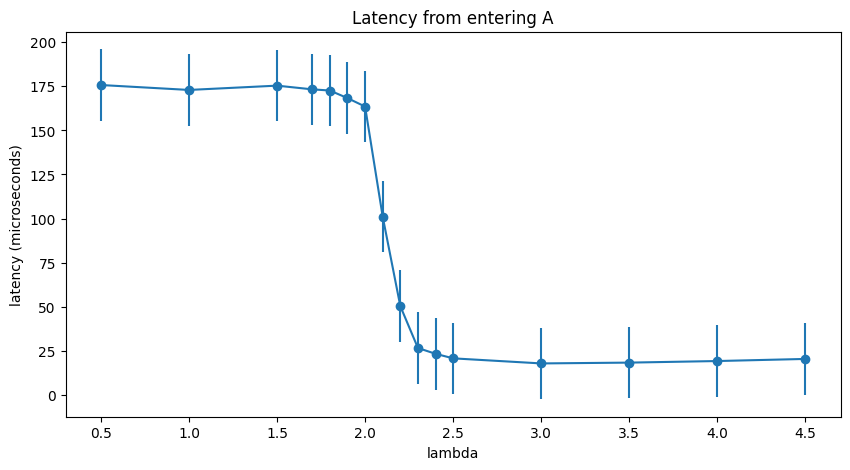

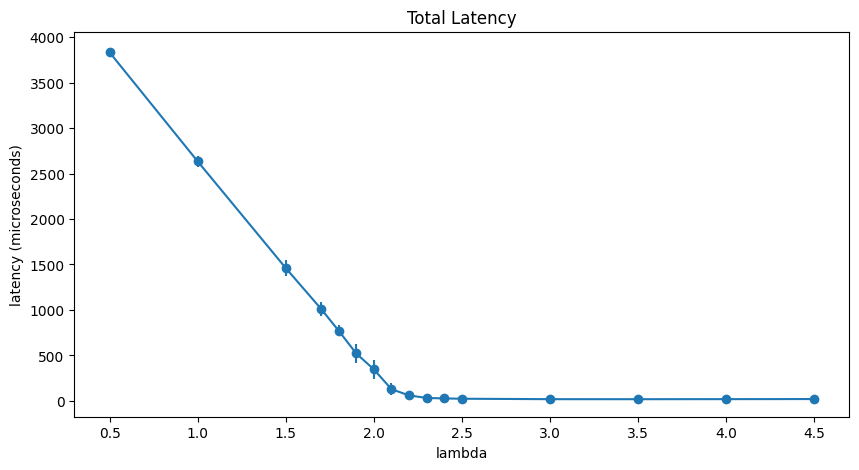

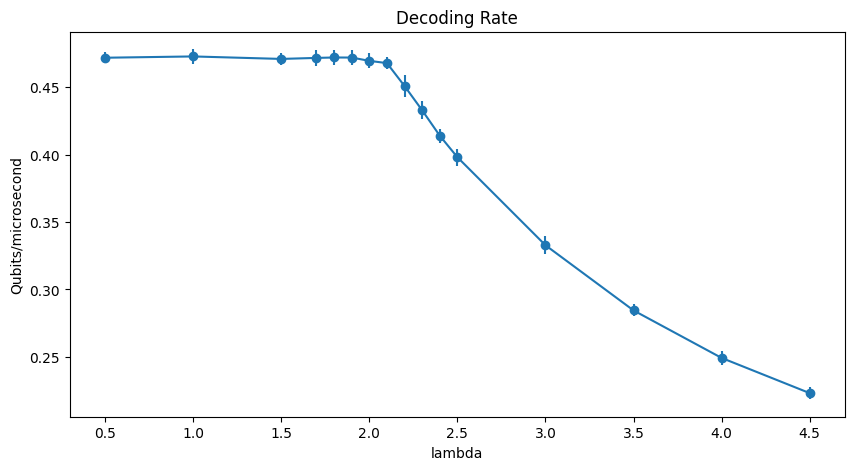

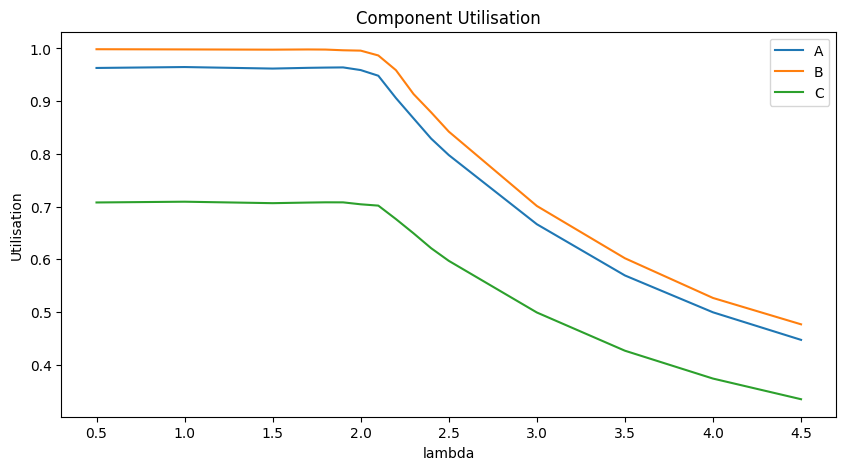

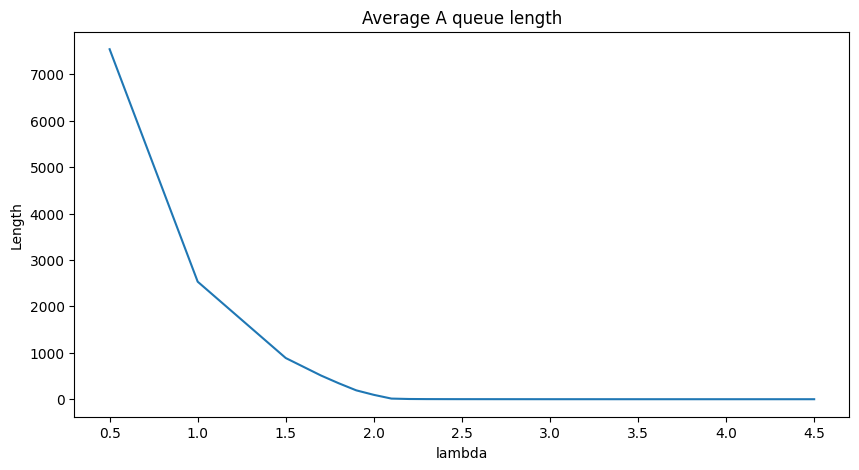

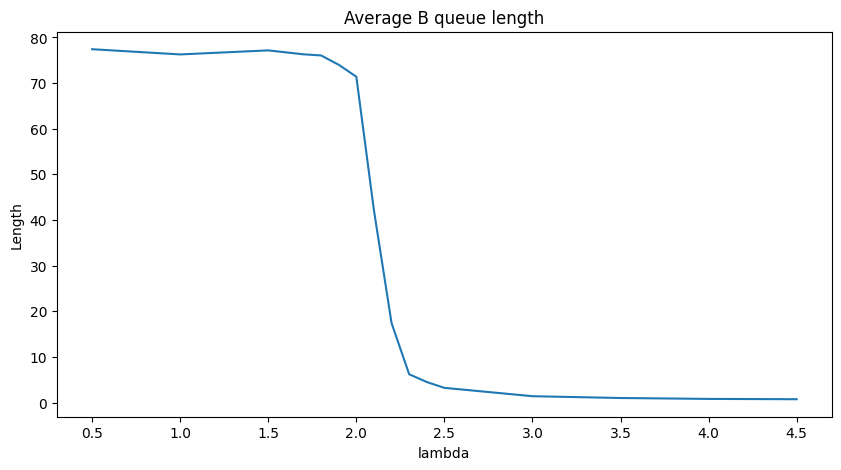

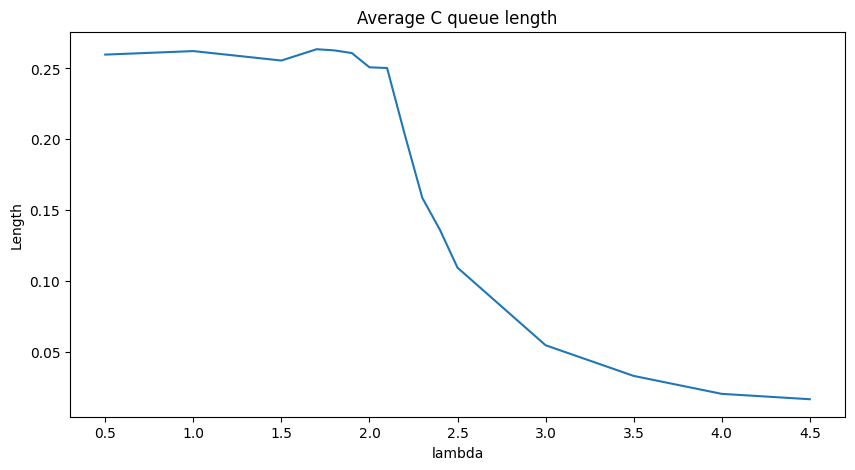

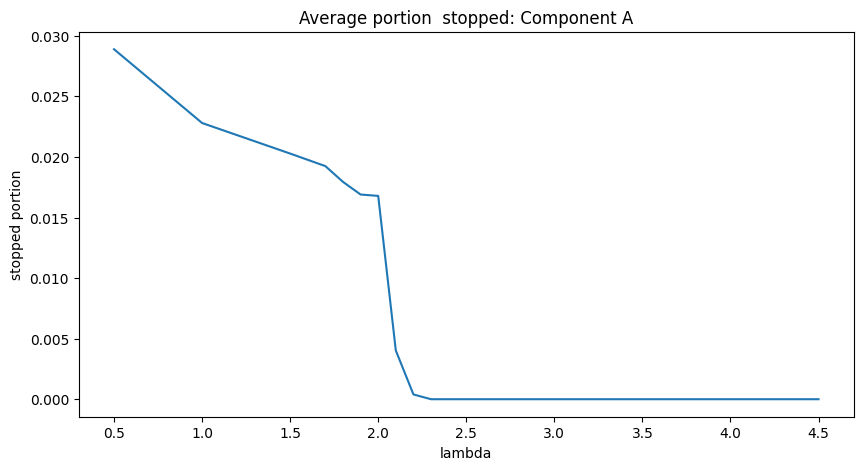

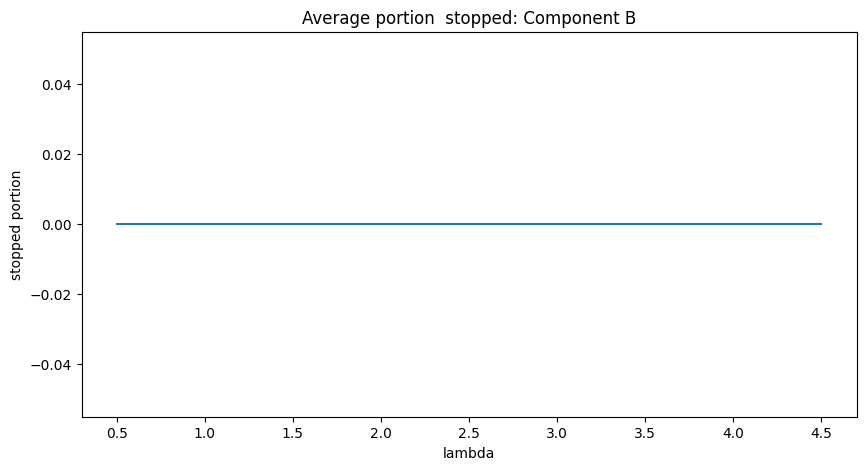

Text(0, 0.5, 'C queue length')

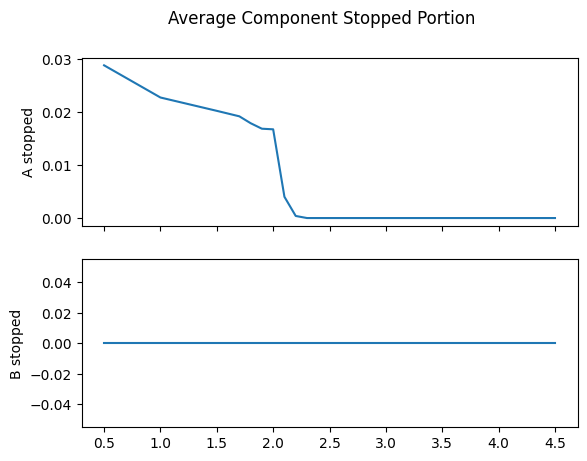

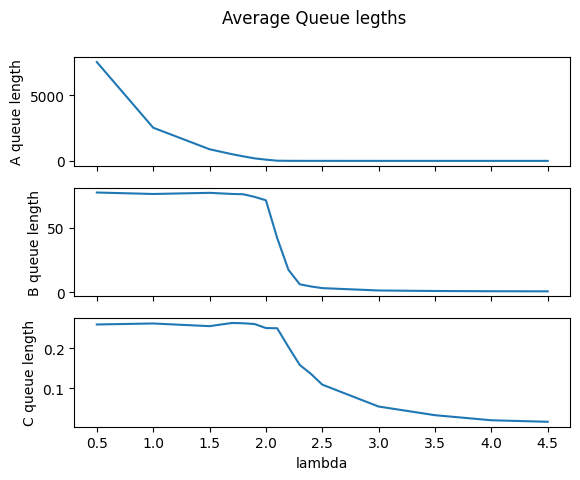

In [15]:
fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, latency_from_a_means[0], latencies_from_a[1], fmt='-o')
plt.title('Latency from entering A')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, total_latency_means[0], total_latency_means[1], fmt='-o')
plt.title('Total Latency')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.errorbar(lams, decoding_rate[0], decoding_rate[1], fmt='-o')
plt.title('Decoding Rate')
plt.xlabel('lambda')
plt.ylabel('Qubits/microsecond')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, a_utilisation_means, label='A')
plt.plot(lams, b_utilisation_means, label='B')
plt.plot(lams, c_utilisation_means, label='C')
plt.title('Component Utilisation')
plt.xlabel('lambda')
plt.ylabel('Utilisation')
plt.legend()
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, a_queue_length_means)
plt.title('Average A queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, b_queue_length_means)
plt.title('Average B queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, c_queue_length_means)
plt.title('Average C queue length')
plt.xlabel('lambda')
plt.ylabel('Length')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, time_stopped_a_means)
plt.title('Average portion  stopped: Component A')
plt.xlabel('lambda')
plt.ylabel('stopped portion')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, time_stopped_b_means)
plt.title('Average portion  stopped: Component B')
plt.xlabel('lambda')
plt.ylabel('stopped portion')
plt.show()

fig, axs = plt.subplots(2, sharex=True)
fig.suptitle(f'Average Component Stopped Portion')
axs[0].plot(lams, time_stopped_a_means)
axs[0].set_ylabel('A stopped')
axs[1].plot(lams, time_stopped_b_means)
axs[1].set_ylabel('B stopped')

fig, axs = plt.subplots(3, sharex=True)
fig.suptitle(f'Average Queue legths')
axs[0].plot(lams, a_queue_length_means)
axs[0].set_ylabel('A queue length')
axs[1].plot(lams, b_queue_length_means)
axs[1].set_ylabel('B queue length')
axs[2].plot(lams, c_queue_length_means)
axs[2].set_xlabel('lambda')
axs[2].set_ylabel('C queue length')

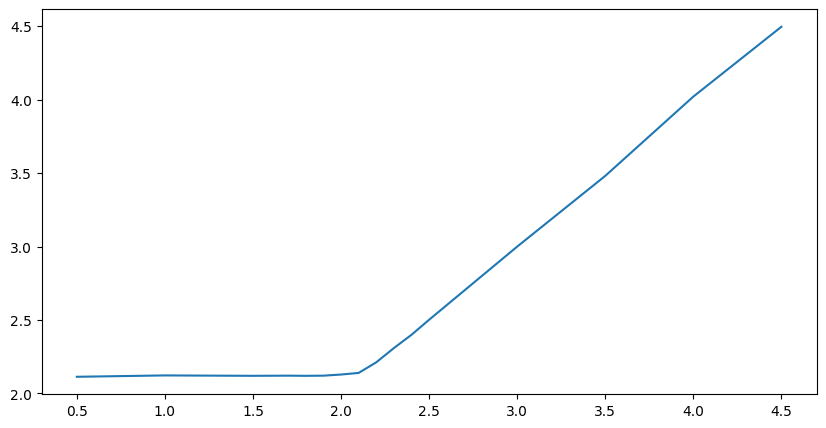

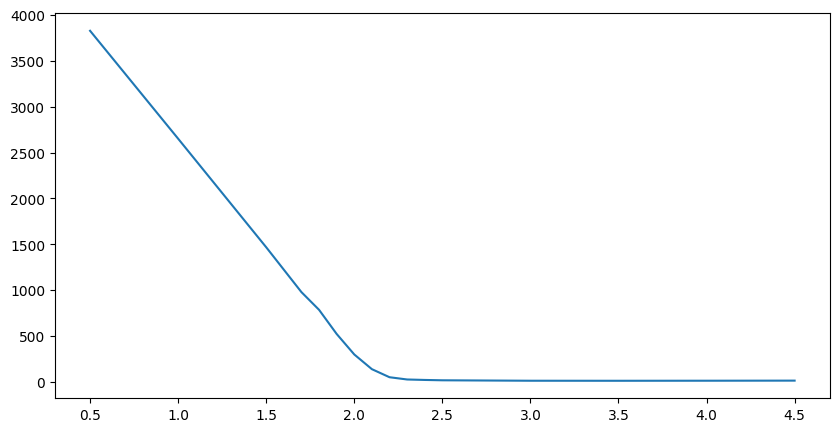

In [ ]:
fig = plt.figure(figsize = (10, 5))
plt.plot(lams, [1/x for x in decoding_rate])
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.show()